# Tugas Praktikum 4: Association Rule
**Dataset:** Online Retail (UCI Machine Learning Repository)  
**Nama / NRP:** Faiz Farrosian Karim / 5054251027

Notebook ini menemukan pola pembelian antar produk pada transaksi ritel online menggunakan algoritma **Apriori** (dibandingkan dengan **FP-Growth**), lalu mengevaluasi aturan asosiasi berdasarkan **support**, **confidence**, dan **lift**.

## 1. Import Dataset

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import time

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 200)

df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
df.shape

(541909, 8)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


**Atribut dataset:** `InvoiceNo` (nomor transaksi; diawali "C" berarti pembatalan), `StockCode` (kode produk), `Description` (nama produk), `Quantity` (jumlah), `InvoiceDate` (waktu transaksi), `UnitPrice` (harga satuan), `CustomerID` (ID pelanggan), dan `Country` (negara).

## 2. Eksplorasi dan Pembersihan Data

### 2.1 Eksplorasi awal

In [4]:
print('Missing value per kolom:')
print(df.isna().sum())
print()
print('Invoice dibatalkan (diawali C):', df['InvoiceNo'].astype(str).str.startswith('C').sum(), 'baris')
print('Quantity <= 0               :', (df['Quantity'] <= 0).sum(), 'baris')
print('Jumlah produk unik          :', df['Description'].nunique())

Missing value per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64



Invoice dibatalkan (diawali C): 9288 baris
Quantity <= 0               : 10624 baris
Jumlah produk unik          : 4223


**Kolom relevan:** `InvoiceNo` sebagai ID transaksi (basket) dan `Description` sebagai item. Kolom lain (harga, pelanggan, negara) tidak diperlukan untuk Association Rule dan hanya dipakai untuk eksplorasi.

### 2.2 Pembersihan data

In [5]:
before_rows, before_inv = len(df), df['InvoiceNo'].nunique()

clean = df.dropna(subset=['Description'])                                   # Description kosong
clean = clean[~clean['InvoiceNo'].astype(str).str.startswith('C')]          # transaksi dibatalkan
clean = clean[clean['Quantity'] > 0].copy()                                 # Quantity negatif / nol
clean['Description'] = clean['Description'].str.strip()                     # rapikan spasi pada nama produk

after_rows, after_inv = len(clean), clean['InvoiceNo'].nunique()

summary = pd.DataFrame({
    'Sebelum': [before_rows, before_inv, df['Description'].nunique()],
    'Sesudah': [after_rows, after_inv, clean['Description'].nunique()],
}, index=['Jumlah baris', 'Jumlah invoice', 'Jumlah produk unik'])
summary['Berkurang'] = summary['Sebelum'] - summary['Sesudah']
summary

,Sebelum,Sesudah,Berkurang
Jumlah baris,541909,530693,11216
Jumlah invoice,25900,20136,5764
Jumlah produk unik,4223,4065,158


Pembersihan membuang baris tanpa deskripsi, invoice pembatalan, dan baris dengan quantity ≤ 0. Pembersihan ini penting agar hanya pembelian yang benar-benar terjadi yang dianalisis, sehingga pola yang ditemukan tidak terdistorsi oleh transaksi yang dibatalkan.

### 2.3 Visualisasi eksplorasi

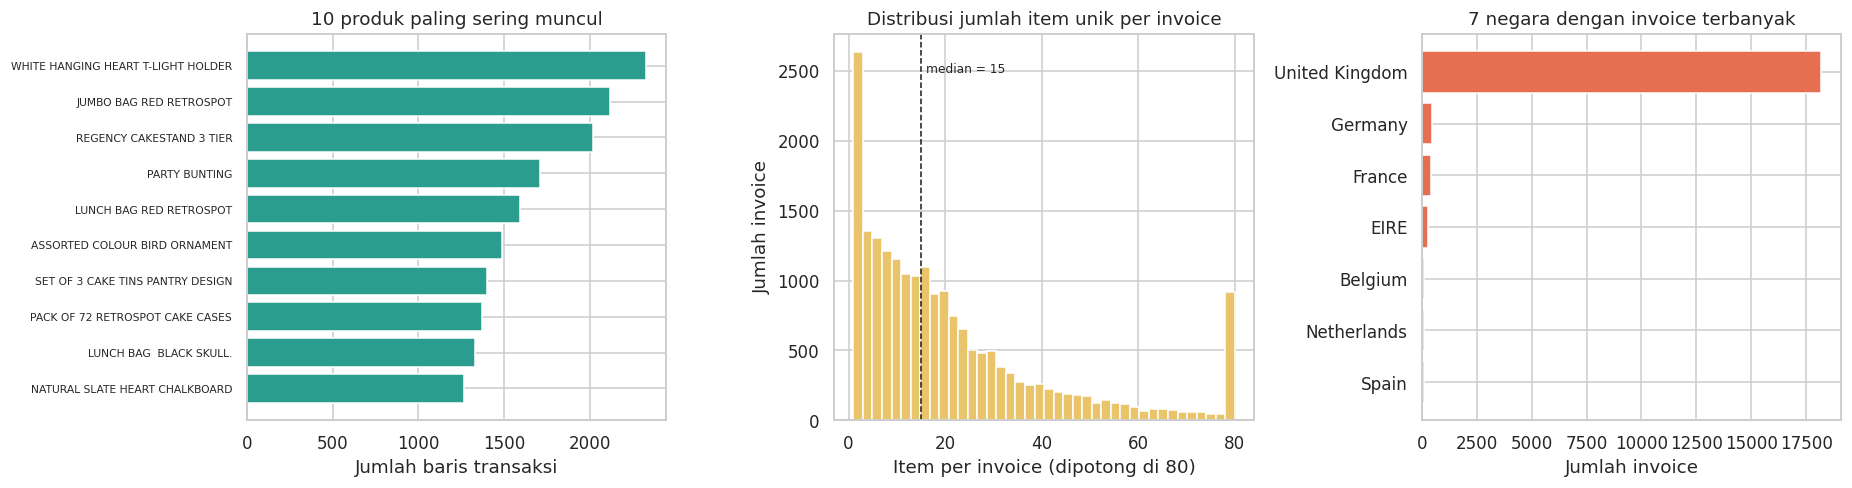

Rata-rata item unik per invoice: 25.8  |  median: 15  |  maks: 1108
Persentase invoice dari United Kingdom: 90.4%


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

# Top 10 produk
top = clean['Description'].value_counts().head(10).sort_values()
ax[0].barh(top.index, top.values, color='#2a9d8f'); ax[0].set_title('10 produk paling sering muncul')
ax[0].set_xlabel('Jumlah baris transaksi'); ax[0].tick_params(axis='y', labelsize=7)

# Distribusi ukuran basket
size = clean.groupby('InvoiceNo')['Description'].nunique()
ax[1].hist(size.clip(upper=80), bins=40, color='#e9c46a', edgecolor='white')
ax[1].set_title('Distribusi jumlah item unik per invoice'); ax[1].set_xlabel('Item per invoice (dipotong di 80)'); ax[1].set_ylabel('Jumlah invoice')
ax[1].axvline(size.median(), color='k', ls='--', lw=1); ax[1].text(size.median()+1, ax[1].get_ylim()[1]*0.9, f'median = {size.median():.0f}', fontsize=8)

# Top negara
ctry = clean.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False).head(7).sort_values()
ax[2].barh(ctry.index, ctry.values, color='#e76f51'); ax[2].set_title('7 negara dengan invoice terbanyak'); ax[2].set_xlabel('Jumlah invoice')

plt.tight_layout(); plt.show()
print(f'Rata-rata item unik per invoice: {size.mean():.1f}  |  median: {size.median():.0f}  |  maks: {size.max()}')
print(f"Persentase invoice dari United Kingdom: {clean[clean.Country=='United Kingdom']['InvoiceNo'].nunique()/after_inv:.1%}")

## 3. Persiapan Data untuk Association Rule

Data diubah menjadi transaksi berbasis invoice (satu invoice = satu *basket* berisi daftar produk unik), lalu di-*one-hot encode*.

In [7]:
# Daftar produk per invoice (transaksi)
transactions = clean.groupby('InvoiceNo')['Description'].apply(lambda s: sorted(set(s)))
print('Jumlah transaksi:', len(transactions))
print('Contoh 3 transaksi:')
for inv, items in transactions.head(3).items():
    print(f'  Invoice {inv}: {items[:5]}{" ..." if len(items) > 5 else ""} ({len(items)} item)')

Jumlah transaksi: 20136
Contoh 3 transaksi:
  Invoice 536365: ['CREAM CUPID HEARTS COAT HANGER', 'GLASS STAR FROSTED T-LIGHT HOLDER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES'] ... (7 item)
  Invoice 536366: ['HAND WARMER RED POLKA DOT', 'HAND WARMER UNION JACK'] (2 item)
  Invoice 536367: ['ASSORTED COLOUR BIRD ORNAMENT', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'BOX OF VINTAGE ALPHABET BLOCKS', 'BOX OF VINTAGE JIGSAW BLOCKS', 'DOORMAT NEW ENGLAND'] ... (12 item)


In [8]:
# One-hot (basket): baris = invoice, kolom = produk, nilai = True/False
basket = (clean.groupby(['InvoiceNo', 'Description']).size().unstack(fill_value=0) > 0)
print('Ukuran basket:', basket.shape)

# Representasi sparse agar hemat memori saat Apriori (4.000+ kolom produk)
basket_sparse = basket.astype(pd.SparseDtype(bool, False))
print(f'Memori dense  : {basket.memory_usage(deep=True).sum()/1e6:.0f} MB')
print(f'Memori sparse : {basket_sparse.memory_usage(deep=True).sum()/1e6:.1f} MB')
print(f'Sparsity      : {1 - basket.values.mean():.2%} sel bernilai False')
basket.iloc[:5, :6]

Ukuran basket: (20136, 4065)


Memori dense  : 83 MB
Memori sparse : 3.3 MB
Sparsity      : 99.36% sel bernilai False


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD
InvoiceNo,,,,,,
536365,False,False,False,False,False,False
536366,False,False,False,False,False,False
536367,False,False,False,False,False,False
536368,False,False,False,False,False,False
536369,False,False,False,False,False,False


## 4. Penerapan Algoritma

### 4.1 Titik awal: min_support = 0.01, min_confidence = 0.5

In [9]:
MIN_SUP, MIN_CONF = 0.01, 0.5

t = time.time()
freq_apriori = apriori(basket_sparse, min_support=MIN_SUP, use_colnames=True, low_memory=True)
t_apriori = time.time() - t

rules = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
freq_apriori['length'] = freq_apriori['itemsets'].apply(len)

print(f'Frequent itemset : {len(freq_apriori)}')
print(freq_apriori['length'].value_counts().sort_index().rename('jumlah').to_frame().T.rename_axis(None, axis=1).to_string())
print(f'Aturan asosiasi  : {len(rules)}')
print(f'Waktu Apriori    : {t_apriori:.2f} detik')

Frequent itemset : 1853
          1    2    3   4  5
jumlah  803  818  215  16  1
Aturan asosiasi  : 841
Waktu Apriori    : 1.61 detik


Pada `min_support = 0.01` dan `min_confidence = 0.5` dihasilkan jumlah aturan yang masih dapat dianalisis (ratusan aturan), tidak terlalu sedikit dan tidak berlebihan, sehingga **nilai awal dipertahankan**. Sebagai pembanding sensitivitas, parameter dicoba diubah di bawah ini.

### 4.2 Sensitivitas parameter

In [10]:
rows = []
for s in [0.005, 0.01, 0.02, 0.03]:
    f = fpgrowth(basket_sparse, min_support=s, use_colnames=True)
    for c in [0.5, 0.7]:
        r = association_rules(f, metric='confidence', min_threshold=c) if len(f) > 1 else []
        rows.append({'min_support': s, 'min_confidence': c, 'frequent itemset': len(f), 'aturan': len(r)})
sens = pd.DataFrame(rows)
sens.pivot(index='min_support', columns='min_confidence', values='aturan').rename_axis(columns='min_conf')

min_conf,0.5,0.7
min_support,,
0.005,25270,10631
0.010,841,260
0.020,61,13
0.030,11,3


- **min_support 0.005** menghasilkan aturan terlalu banyak (didominasi pola yang sangat spesifik dan banyak variasi produk sejenis), sehingga sulit diinterpretasi.
- **min_support 0.02–0.03** menghasilkan aturan terlalu sedikit dan hanya memunculkan produk yang sangat populer.
- **min_support 0.01 dan min_confidence 0.5** memberi keseimbangan: cukup banyak aturan untuk dibandingkan, tetapi setiap aturan masih didukung oleh ±200 invoice atau lebih.

### 4.3 Perbandingan Apriori vs FP-Growth

In [11]:
t = time.time(); freq_fp = fpgrowth(basket_sparse, min_support=MIN_SUP, use_colnames=True); t_fp = time.time() - t

same = set(freq_apriori['itemsets']) == set(freq_fp['itemsets'])
pd.DataFrame({'Frequent itemset': [len(freq_apriori), len(freq_fp)],
              'Waktu (detik)': [round(t_apriori, 2), round(t_fp, 2)]},
             index=['Apriori', 'FP-Growth']).assign(**{'Hasil identik': [same, same]})

,Frequent itemset,Waktu (detik),Hasil identik
Apriori,1853,1.61,True
FP-Growth,1853,4.86,True


Kedua algoritma menghasilkan frequent itemset yang identik (sesuai teori); perbedaannya hanya pada efisiensi. Analisis selanjutnya memakai hasil **Apriori**.

## 5. Evaluasi Aturan Asosiasi

### 5.1 Daftar aturan (diurutkan berdasarkan lift)

In [12]:
def fmt(s): return ', '.join(sorted(s))
R = rules.copy()
R['antecedents'] = R['antecedents'].apply(fmt)
R['consequents'] = R['consequents'].apply(fmt)
R = R.sort_values('lift', ascending=False).reset_index(drop=True)
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']

print('Statistik ringkas aturan:')
print(R[['support', 'confidence', 'lift']].describe().round(3).to_string())
print(f"\nAturan dengan lift > 1 : {(R['lift'] > 1).sum()} dari {len(R)}")
R[cols].head(15).round(3)

Statistik ringkas aturan:
       support  confidence     lift
count  841.000     841.000  841.000
mean     0.014       0.650   17.528
std      0.004       0.110   13.856
min      0.010       0.500    4.819
25%      0.011       0.557    9.442
50%      0.012       0.627   12.663
75%      0.014       0.729   18.903
max      0.041       0.959   80.220

Aturan dengan lift > 1 : 841 dari 841


,antecedents,consequents,support,confidence,lift
0,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010,0.857,80.220
1,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010,0.944,80.220
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010,0.846,79.961
3,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010,0.953,79.961
4,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011,0.921,78.236
5,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011,0.932,78.236
6,"HERB MARKER ROSEMARY, HERB MARKER THYME",HERB MARKER PARSLEY,0.010,0.919,77.714
7,HERB MARKER PARSLEY,"HERB MARKER ROSEMARY, HERB MARKER THYME",0.010,0.853,77.714
8,HERB MARKER THYME,HERB MARKER PARSLEY,0.011,0.899,76.037
9,HERB MARKER PARSLEY,HERB MARKER THYME,0.011,0.895,76.037


### 5.2 Visualisasi aturan

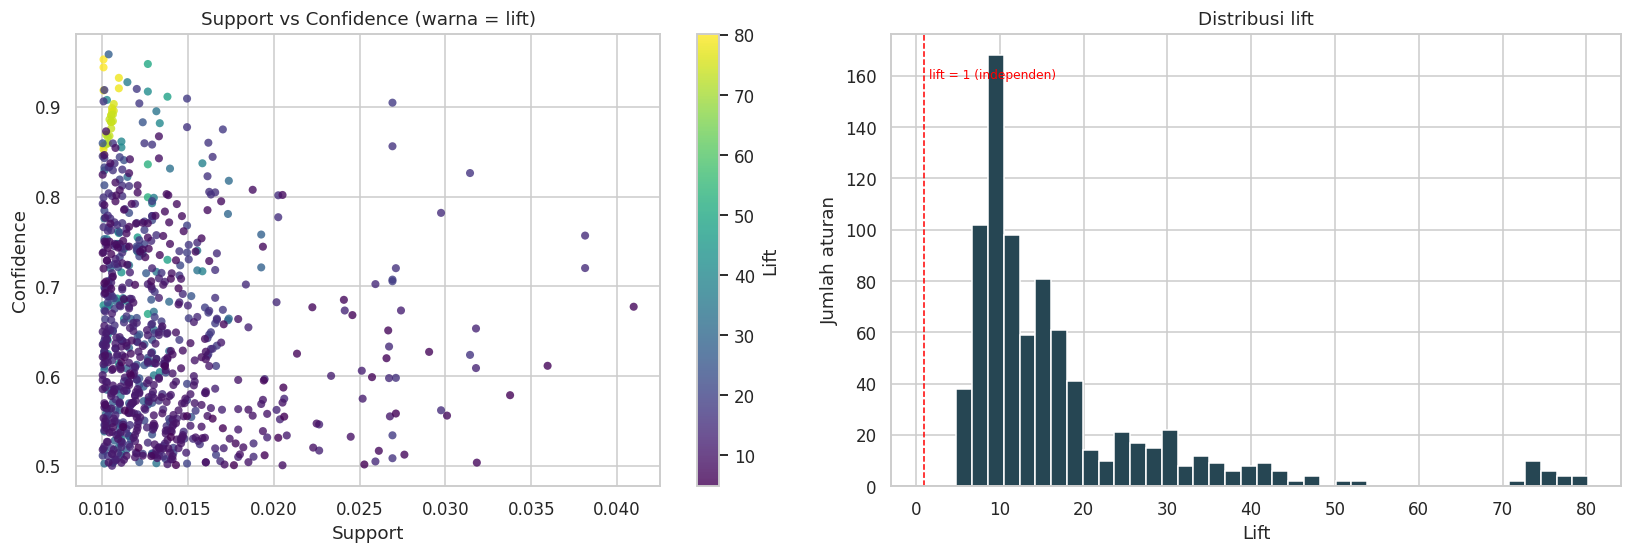

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))

sc = ax[0].scatter(R['support'], R['confidence'], c=R['lift'], cmap='viridis', s=28, alpha=0.8, edgecolor='none')
ax[0].set_xlabel('Support'); ax[0].set_ylabel('Confidence'); ax[0].set_title('Support vs Confidence (warna = lift)')
plt.colorbar(sc, ax=ax[0], label='Lift')

ax[1].hist(R['lift'], bins=40, color='#264653', edgecolor='white')
ax[1].axvline(1, color='red', ls='--', lw=1); ax[1].text(1.5, ax[1].get_ylim()[1]*0.9, 'lift = 1 (independen)', color='red', fontsize=8)
ax[1].set_xlabel('Lift'); ax[1].set_ylabel('Jumlah aturan'); ax[1].set_title('Distribusi lift')
plt.tight_layout(); plt.show()

### 5.3 Tiga aturan terbaik berdasarkan lift

Aturan asosiasi bersifat dua arah dan sering muncul berulang (A→B, B→A, A,B→C, dst.) dengan lift hampir sama, apalagi bila produknya satu seri. Jika diambil mentah, tiga aturan teratas akan membahas produk yang sama. Karena itu pemilihan dilakukan secara *greedy*: urutkan semua aturan berdasarkan **lift** (seri → confidence), lalu ambil aturan berikutnya **hanya jika tidak berbagi item** dengan aturan terpilih sebelumnya. Hasilnya tiga pola yang berbeda dan lebih informatif.

In [14]:
ranked = (rules.assign(A=rules['antecedents'].apply(fmt), B=rules['consequents'].apply(fmt),
                       items=rules.apply(lambda r: frozenset(r['antecedents']) | frozenset(r['consequents']), axis=1))
               .sort_values(['lift', 'confidence'], ascending=False))

picked, used = [], set()
for _, r in ranked.iterrows():
    if r['items'] & used: continue
    picked.append(r); used |= r['items']
    if len(picked) == 10: break

top_pairs = pd.DataFrame(picked)[['A', 'B', 'support', 'confidence', 'lift']].rename(columns={'A': 'antecedents', 'B': 'consequents'}).reset_index(drop=True)
top_pairs.index += 1
print('Kandidat 10 aturan teratas tanpa tumpang tindih item (3 teratas = aturan terbaik):')
top_pairs.round(3)

Kandidat 10 aturan teratas tanpa tumpang tindih item (3 teratas = aturan terbaik):


,antecedents,consequents,support,confidence,lift
1,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010,0.944,80.220
2,HERB MARKER MINT,HERB MARKER BASIL,0.010,0.867,72.112
3,REGENCY TEA PLATE PINK,"REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES",0.013,0.836,52.774
4,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.011,0.747,47.180
5,REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,0.012,0.755,46.188
6,"POPPY'S PLAYHOUSE BEDROOM, POPPY'S PLAYHOUSE KITCHEN",POPPY'S PLAYHOUSE LIVINGROOM,0.011,0.716,43.934
7,JAM JAR WITH GREEN LID,JAM JAR WITH PINK LID,0.011,0.742,43.677
8,CHILDRENS CUTLERY DOLLY GIRL,CHILDRENS CUTLERY SPACEBOY,0.011,0.759,42.479
9,PINK POLKADOT CUP,BLUE POLKADOT CUP,0.010,0.678,41.977
10,BLUE POLKADOT BOWL,PINK POLKADOT BOWL,0.010,0.646,39.060


In [15]:
top3 = top_pairs.head(3).copy()
tot = len(basket)
for i, r in top3.iterrows():
    print(f'Aturan #{i}')
    print(f"  JIKA membeli  : {r['antecedents']}")
    print(f"  MAKA membeli  : {r['consequents']}")
    print(f"  support={r['support']:.4f} (~{int(round(r['support']*tot))} invoice) | confidence={r['confidence']:.3f} | lift={r['lift']:.1f}")
    print()

Aturan #1
  JIKA membeli  : HERB MARKER PARSLEY, HERB MARKER ROSEMARY
  MAKA membeli  : HERB MARKER THYME
  support=0.0101 (~203 invoice) | confidence=0.944 | lift=80.2

Aturan #2
  JIKA membeli  : HERB MARKER MINT
  MAKA membeli  : HERB MARKER BASIL
  support=0.0103 (~208 invoice) | confidence=0.867 | lift=72.1

Aturan #3
  JIKA membeli  : REGENCY TEA PLATE PINK
  MAKA membeli  : REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES
  support=0.0127 (~255 invoice) | confidence=0.836 | lift=52.8



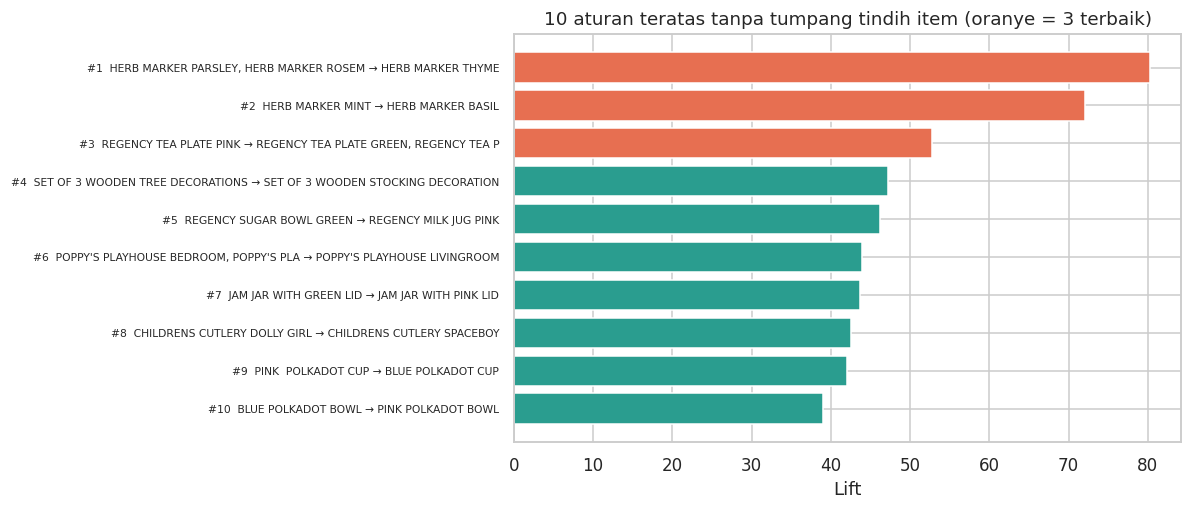

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.8))
lab = [f"#{i}  {r['antecedents'][:38]} → {r['consequents'][:38]}" for i, r in top_pairs.iterrows()]
colors = ['#e76f51'] * 3 + ['#2a9d8f'] * (len(top_pairs) - 3)
ax.barh(lab[::-1], top_pairs['lift'][::-1], color=colors[::-1])
ax.set_xlabel('Lift'); ax.set_title('10 aturan teratas tanpa tumpang tindih item (oranye = 3 terbaik)'); ax.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

### 5.4 Interpretasi tiga aturan terbaik dalam konteks bisnis ritel

In [17]:
from IPython.display import Markdown, display
txt = ''
for i, r in top3.iterrows():
    k = int(round(r['support'] * tot))
    txt += (f"**Aturan #{i}: {r['antecedents']} → {r['consequents']}**  \n"
            f"Pelanggan yang membeli *{r['antecedents']}* memiliki peluang **{r['confidence']:.0%}** untuk juga membeli *{r['consequents']}*. "
            f"Kombinasi ini muncul pada ±{k} invoice ({r['support']:.2%} dari seluruh transaksi). "
            f"Nilai lift **{r['lift']:.1f}** berarti peluang membeli konsekuen **{r['lift']:.1f} kali lebih besar** dibandingkan peluang dasarnya "
            f"jika kedua produk dibeli secara independen.\n\n")
display(Markdown(txt))

**Aturan #1: HERB MARKER PARSLEY, HERB MARKER ROSEMARY → HERB MARKER THYME**  
Pelanggan yang membeli *HERB MARKER PARSLEY, HERB MARKER ROSEMARY* memiliki peluang **94%** untuk juga membeli *HERB MARKER THYME*. Kombinasi ini muncul pada ±203 invoice (1.01% dari seluruh transaksi). Nilai lift **80.2** berarti peluang membeli konsekuen **80.2 kali lebih besar** dibandingkan peluang dasarnya jika kedua produk dibeli secara independen.

**Aturan #2: HERB MARKER MINT → HERB MARKER BASIL**  
Pelanggan yang membeli *HERB MARKER MINT* memiliki peluang **87%** untuk juga membeli *HERB MARKER BASIL*. Kombinasi ini muncul pada ±208 invoice (1.03% dari seluruh transaksi). Nilai lift **72.1** berarti peluang membeli konsekuen **72.1 kali lebih besar** dibandingkan peluang dasarnya jika kedua produk dibeli secara independen.

**Aturan #3: REGENCY TEA PLATE PINK → REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES**  
Pelanggan yang membeli *REGENCY TEA PLATE PINK* memiliki peluang **84%** untuk juga membeli *REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES*. Kombinasi ini muncul pada ±255 invoice (1.27% dari seluruh transaksi). Nilai lift **52.8** berarti peluang membeli konsekuen **52.8 kali lebih besar** dibandingkan peluang dasarnya jika kedua produk dibeli secara independen.



**Implikasi bisnis (ringkas):**
1. **Bundling / paket produk** – produk yang hampir selalu dibeli bersama (satu seri/varian) cocok dijual sebagai *set* dengan harga paket untuk menaikkan nilai keranjang.
2. **Penempatan & rekomendasi** – tampilkan produk konsekuen sebagai "sering dibeli bersama" pada halaman produk antecedent dan di keranjang belanja.
3. **Manajemen stok** – karena permintaan produk dalam satu pola cenderung naik bersamaan, stok produk-produk tersebut perlu dijaga seimbang agar tidak terjadi *stockout* pada salah satu produk.
4. **Promosi silang (cross-selling)** – diskon pada satu produk dapat mendorong penjualan produk pasangannya.

**Catatan:** pelanggan pada dataset ini sebagian besar adalah pedagang grosir (*wholesaler*), sehingga pola "dibeli bersama" juga mencerminkan pembelian satu set lengkap untuk dijual kembali.

### 5.5 Aturan dengan confidence tertinggi (pembanding)

In [18]:
R.sort_values(['confidence', 'lift'], ascending=False)[cols].head(8).round(3)

,antecedents,consequents,support,confidence,lift
133,"JAM MAKING SET PRINTED, SUKI SHOULDER BAG",DOTCOM POSTAGE,0.010,0.959,27.267
3,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010,0.953,79.961
28,"REGENCY TEA PLATE PINK, REGENCY TEA PLATE ROSES",REGENCY TEA PLATE GREEN,0.013,0.948,50.100
1,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010,0.944,80.220
5,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011,0.932,78.236
67,"WOODEN HEART CHRISTMAS SCANDINAVIAN, WOODEN TREE CHRISTMAS SCANDINAVIAN",WOODEN STAR CHRISTMAS SCANDINAVIAN,0.011,0.928,36.485
4,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011,0.921,78.236
237,"CHARLOTTE BAG PINK POLKADOT, STRAWBERRY CHARLOTTE BAG, WOODLAND CHARLOTTE BAG",RED RETROSPOT CHARLOTTE BAG,0.012,0.920,17.919


## 6. Kesimpulan

In [19]:
n_sets_by_len = freq_apriori['length'].value_counts().sort_index().to_dict()
display(Markdown(f'''
1. **Pembersihan data**: dari **{before_rows:,}** baris / **{before_inv:,}** invoice menjadi **{after_rows:,}** baris / **{after_inv:,}** invoice setelah membuang Description kosong, invoice pembatalan, dan Quantity ≤ 0.
2. **Persiapan**: {basket.shape[0]:,} transaksi × {basket.shape[1]:,} produk dalam format one-hot (matriks sangat sparse, {1 - basket.values.mean():.1%} kosong).
3. **Algoritma**: Apriori dan FP-Growth menghasilkan **{len(freq_apriori)} frequent itemset** yang identik pada `min_support = 0.01`; dengan `min_confidence = 0.5` diperoleh **{len(rules)} aturan asosiasi** (semuanya memiliki lift > 1).
4. **Pola yang ditemukan**: aturan dengan lift tertinggi didominasi **produk-produk sejenis dalam satu seri** (varian warna/jenis dari produk yang sama) yang dibeli bersamaan. Pola ini kuat dan konsisten, bukan kebetulan, karena lift jauh di atas 1.
5. **Rekomendasi**: manfaatkan pola tersebut untuk bundling, rekomendasi "sering dibeli bersama", serta perencanaan stok produk berpasangan.
6. **Keterbatasan**: support minimum 0.01 hanya menangkap produk yang cukup populer; lift tinggi pada produk sejenis relatif "mudah ditebak", sehingga untuk menemukan pola yang lebih tidak terduga dapat dicoba menurunkan support dan menyaring aturan antar-kategori produk berbeda.
'''))


1. **Pembersihan data**: dari **541,909** baris / **25,900** invoice menjadi **530,693** baris / **20,136** invoice setelah membuang Description kosong, invoice pembatalan, dan Quantity ≤ 0.
2. **Persiapan**: 20,136 transaksi × 4,065 produk dalam format one-hot (matriks sangat sparse, 99.4% kosong).
3. **Algoritma**: Apriori dan FP-Growth menghasilkan **1853 frequent itemset** yang identik pada `min_support = 0.01`; dengan `min_confidence = 0.5` diperoleh **841 aturan asosiasi** (semuanya memiliki lift > 1).
4. **Pola yang ditemukan**: aturan dengan lift tertinggi didominasi **produk-produk sejenis dalam satu seri** (varian warna/jenis dari produk yang sama) yang dibeli bersamaan. Pola ini kuat dan konsisten, bukan kebetulan, karena lift jauh di atas 1.
5. **Rekomendasi**: manfaatkan pola tersebut untuk bundling, rekomendasi "sering dibeli bersama", serta perencanaan stok produk berpasangan.
6. **Keterbatasan**: support minimum 0.01 hanya menangkap produk yang cukup populer; lift tinggi pada produk sejenis relatif "mudah ditebak", sehingga untuk menemukan pola yang lebih tidak terduga dapat dicoba menurunkan support dan menyaring aturan antar-kategori produk berbeda.
